<a href="https://colab.research.google.com/github/lokeshraju1/Google-Maps-Reviews-LLMs/blob/main/Diamond.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install statsmodels

In [2]:
!pip install tensorflow

In [3]:
!pip install keras

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
import pickle

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [5]:
# 1. Load Dataset & Deduplicate
df = pd.read_csv('diamonds.csv')
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

if df.duplicated().sum() > 0:
    df = df.drop_duplicates(keep='first')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53794 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53794 non-null  float64
 1   cut      53794 non-null  object 
 2   color    53794 non-null  object 
 3   clarity  53794 non-null  object 
 4   depth    53794 non-null  float64
 5   table    53794 non-null  float64
 6   price    53794 non-null  int64  
 7   x        53794 non-null  float64
 8   y        53794 non-null  float64
 9   z        53794 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.5+ MB


In [6]:
# 1.1 Raw data Skewness checking
numerical_cols = ['carat', 'price', 'x', 'y', 'z']
categorical_cols = ['cut', 'color', 'clarity']

df[numerical_cols].skew()

,0
carat,1.113651
price,1.618240
x,0.379624
y,2.445768
z,1.529023


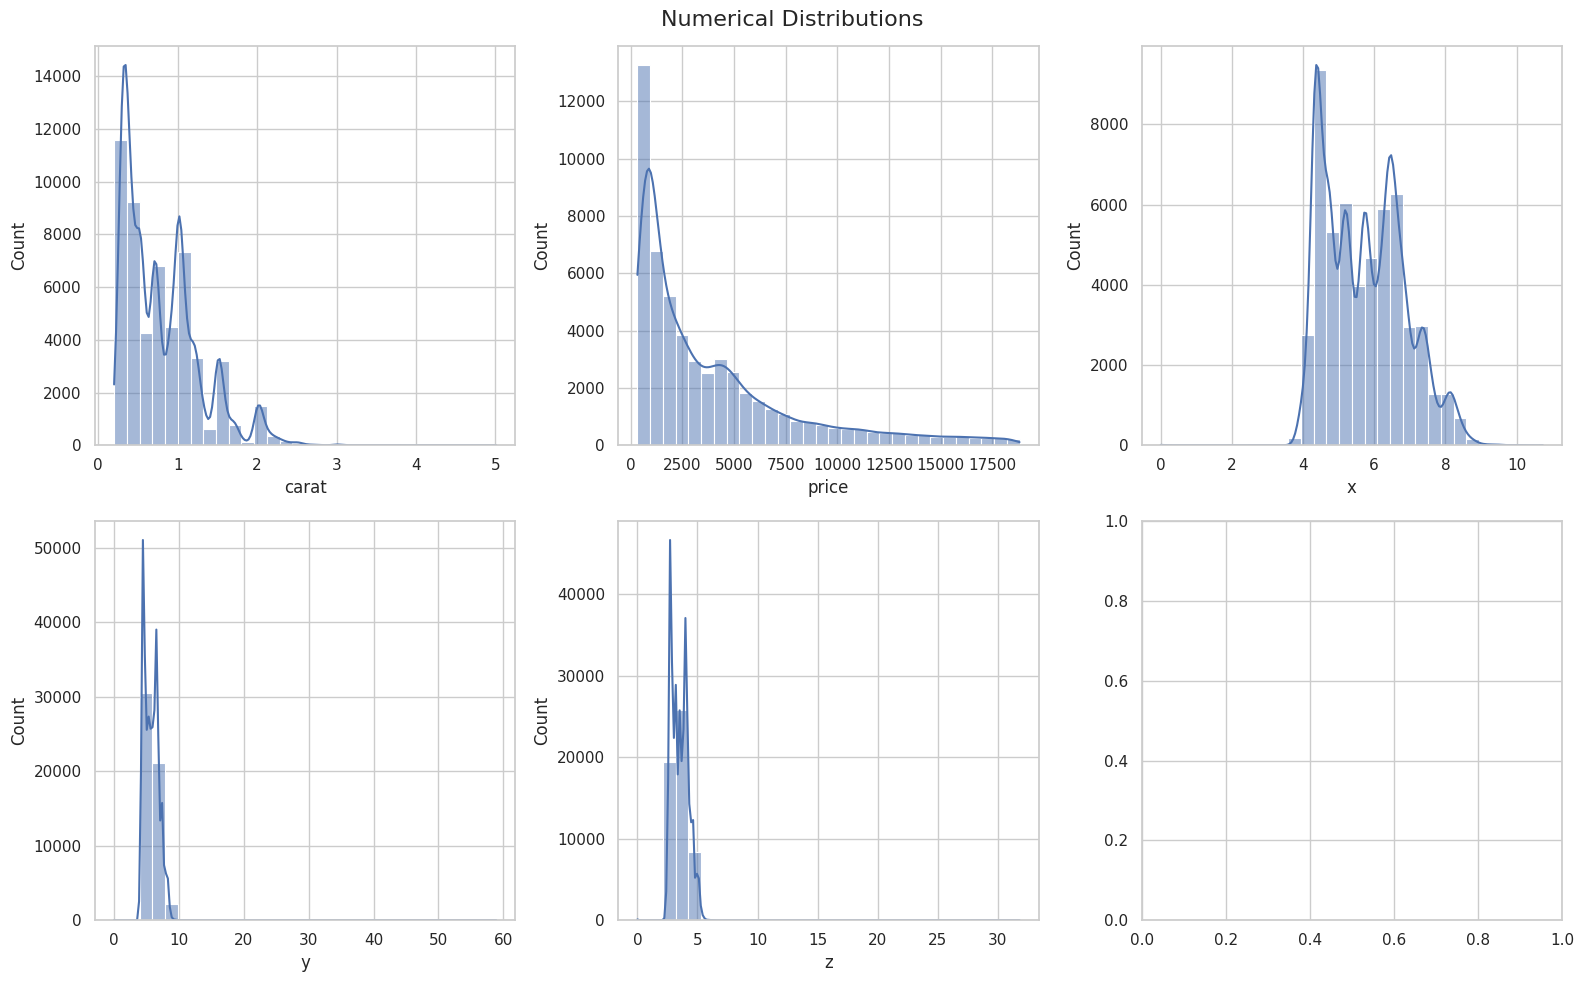

In [7]:
# 1.2 Raw data distribution checking
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i//3, i%3])
plt.suptitle("Numerical Distributions", fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
# 2. Outlier Handling (IQR Method)
def apply_iqr_filter(dataframe, columns):
    df_clean = dataframe.copy()
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        df_clean = df_clean[(df_clean[col] >= Q1 - 1.5 * IQR) & (df_clean[col] <= Q3 + 1.5 * IQR)]
    return df_clean

numerical_cols = ['carat', 'price', 'x', 'y', 'z']
df = apply_iqr_filter(df, numerical_cols)

In [9]:
# 3. Skewness Handling (Log Transform)
for col in numerical_cols:
    if df[col].skew() > 0.75:
        df[f'{col}_log'] = np.log1p(df[col])

df[numerical_cols].skew()

,0
carat,0.657875
price,1.125809
x,0.217930
y,0.212450
z,0.218858


In [10]:
# 4. Feature Engineering
df['price_inr'] = df['price'] * 92.58  # Dynamic market valuation metric
df['volume'] = df['x'] * df['y'] * df['z']
df['price_per_carat'] = df['price'] / df['carat']
df['dimension_ratio'] = (df['x'] + df['y']) / (2 * (df['z'] + 1e-6))

# Categorizing assets by weight
bins = [0, 0.5, 1.5, np.inf]
df['carat_category'] = pd.cut(df['carat'], bins=bins, labels=['Light', 'Medium', 'Heavy'])

print(f"Dataset ready for analysis. Shape: {df.shape}")

display(df.head(1))

Dataset ready for analysis. Shape: (49376, 16)


,carat,cut,color,clarity,depth,table,price,x,y,z,price_log,price_inr,volume,price_per_carat,dimension_ratio,carat_category
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,5.78996,30181.08,38.20203,1417.391304,1.631687,Light


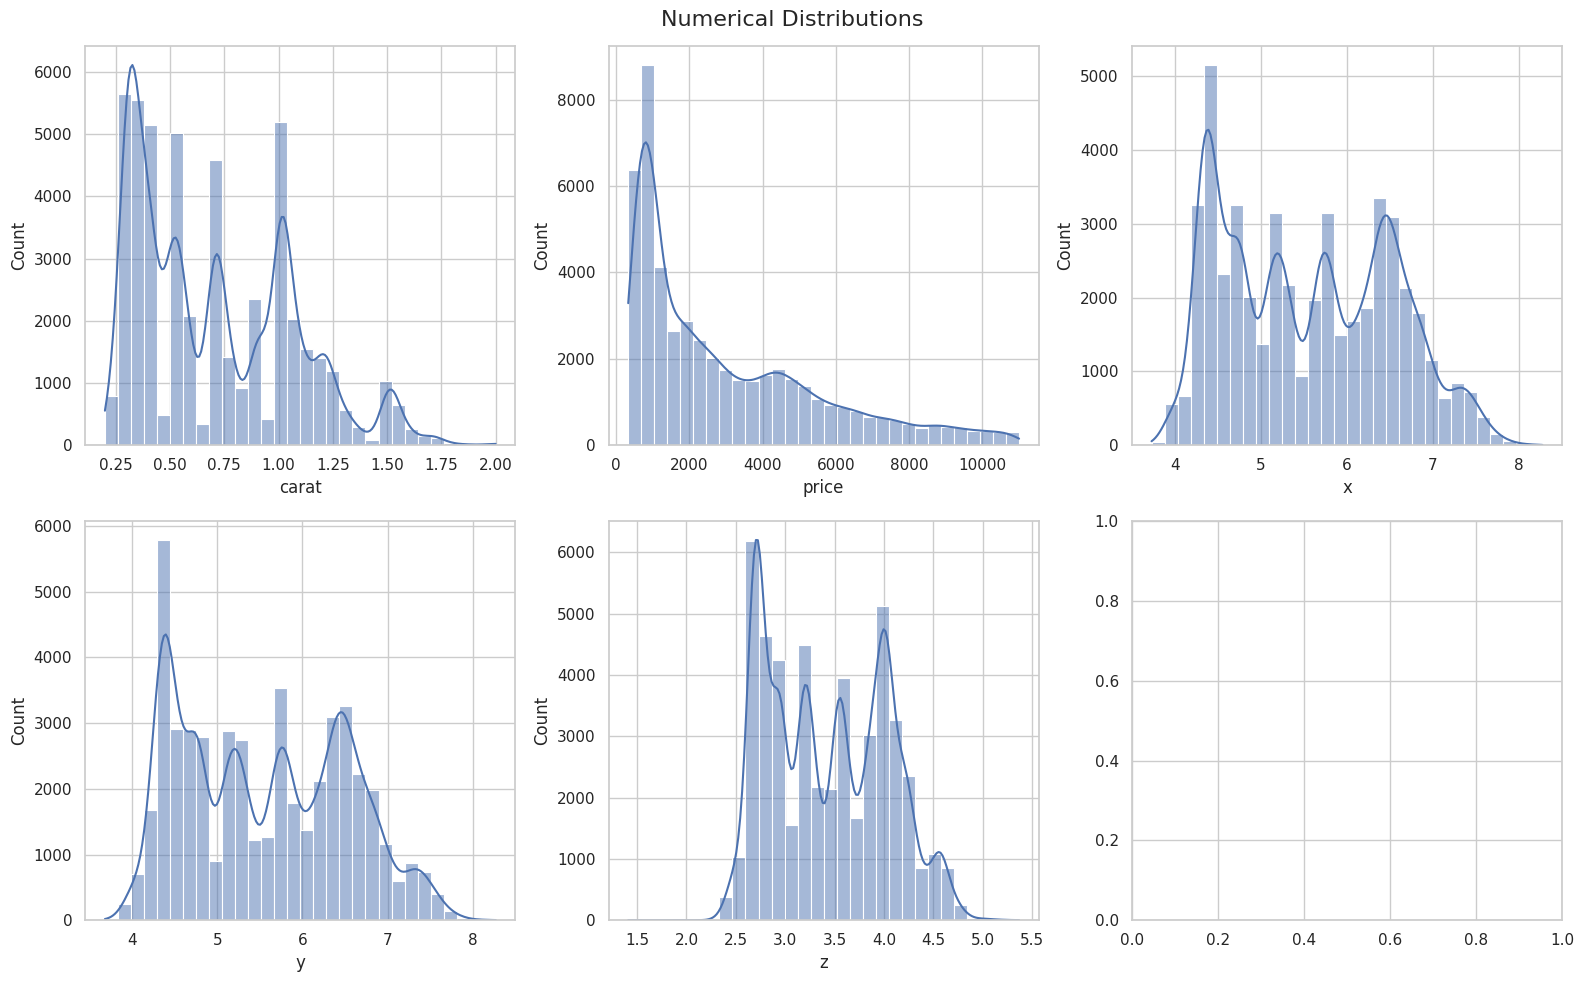

In [11]:
# 1. Distributions of core metrics
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i//3, i%3])
plt.suptitle("Numerical Distributions", fontsize=16)
plt.tight_layout()
plt.show()

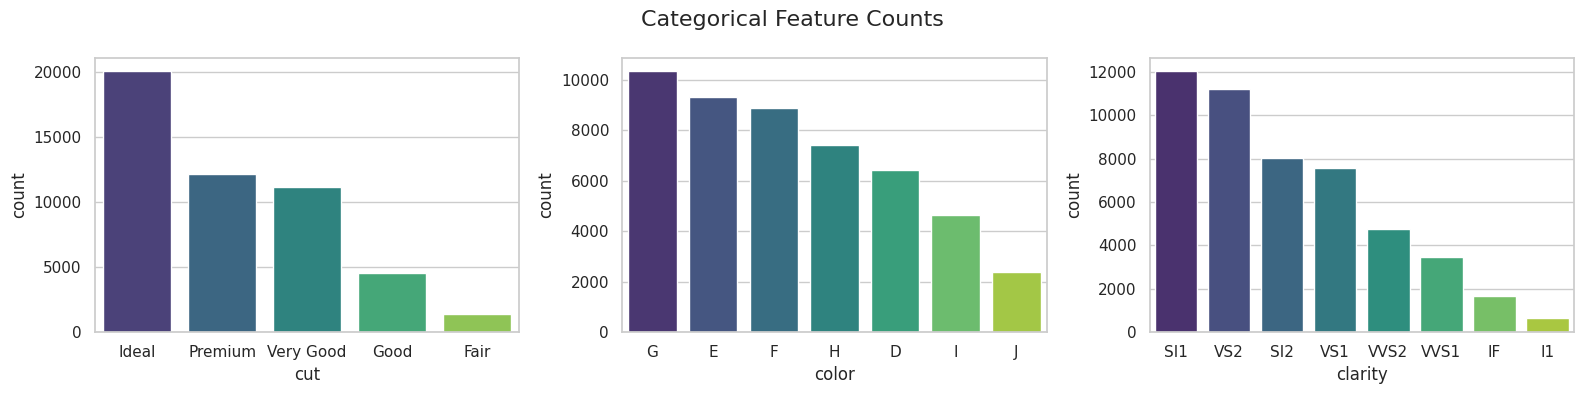

In [12]:
# 2. Categorical Counts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(['cut', 'color', 'clarity']):
    sns.countplot(data=df, x=col, ax=axes[i], palette='viridis', order=df[col].value_counts().index)
plt.suptitle("Categorical Feature Counts", fontsize=16)
plt.tight_layout()
plt.show()

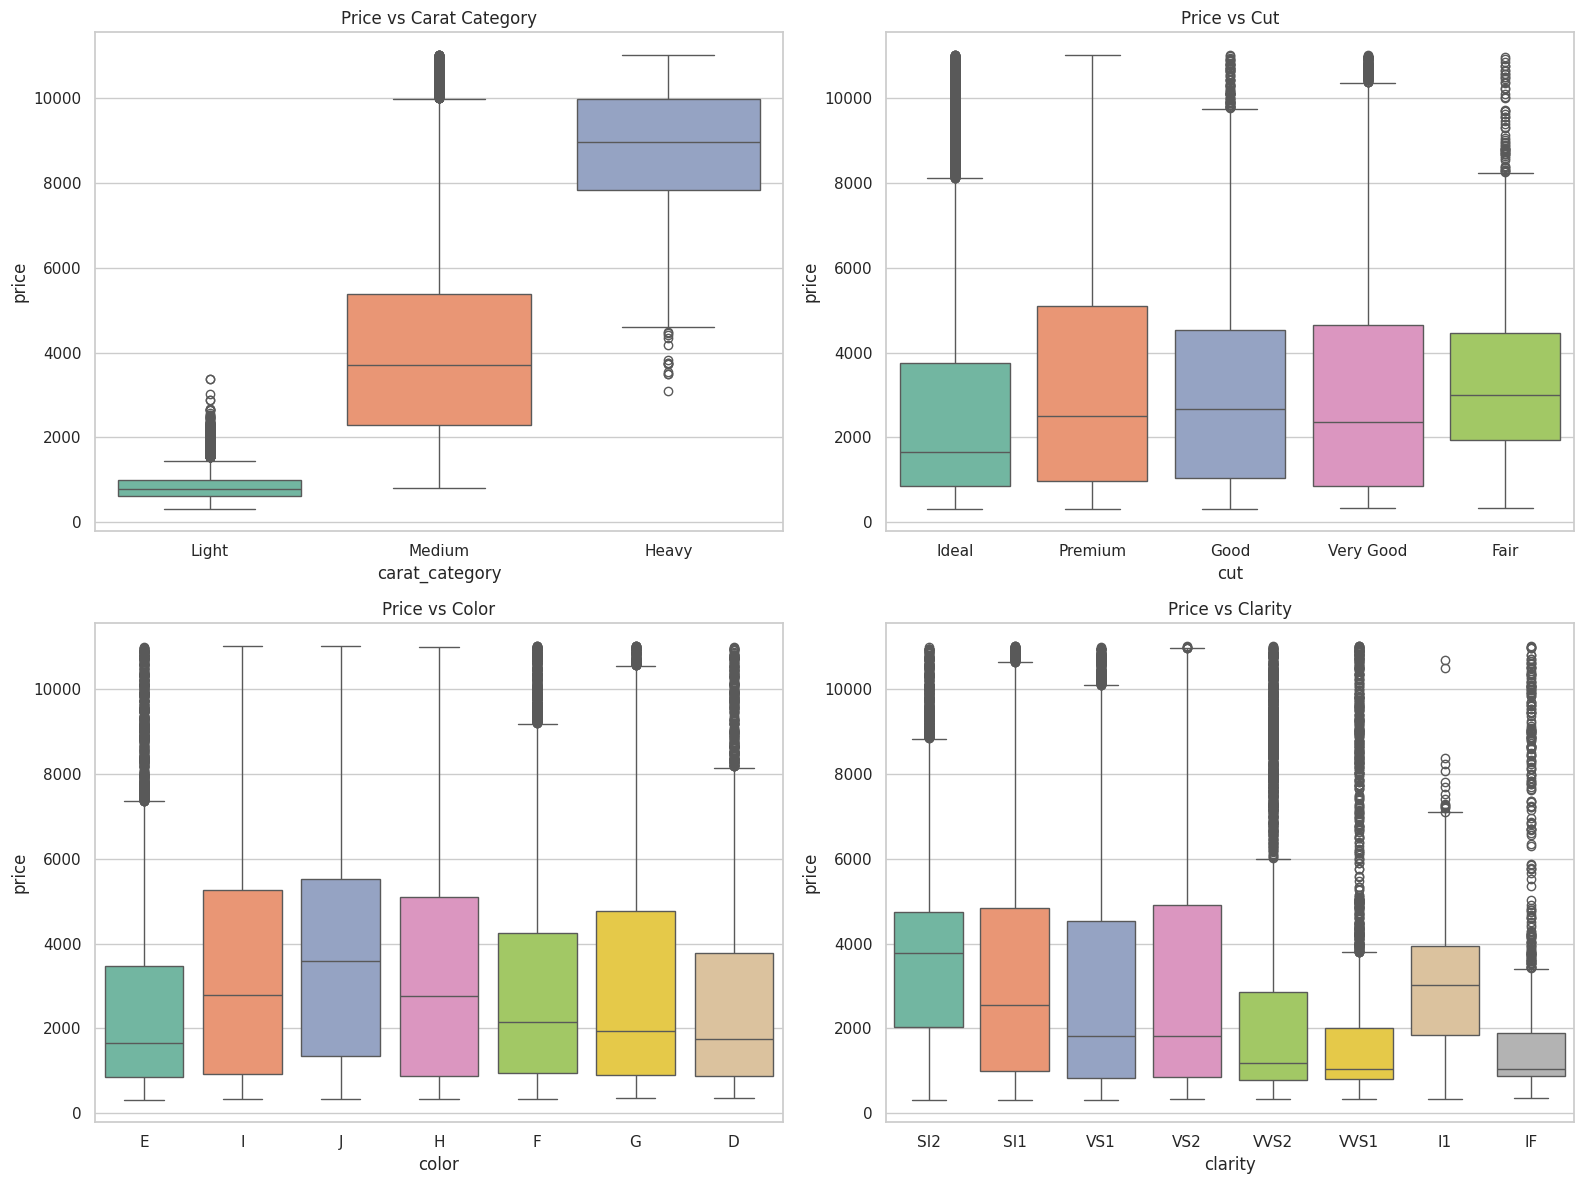

In [13]:
# 3. Price Variation Boxplots (Using the engineered 'carat_category'!)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.boxplot(data=df, x='carat_category', y='price', ax=axes[0,0], palette='Set2').set_title('Price vs Carat Category')
sns.boxplot(data=df, x='cut', y='price', ax=axes[0,1], palette='Set2').set_title('Price vs Cut')
sns.boxplot(data=df, x='color', y='price', ax=axes[1,0], palette='Set2').set_title('Price vs Color')
sns.boxplot(data=df, x='clarity', y='price', ax=axes[1,1], palette='Set2').set_title('Price vs Clarity')
plt.tight_layout()
plt.show()

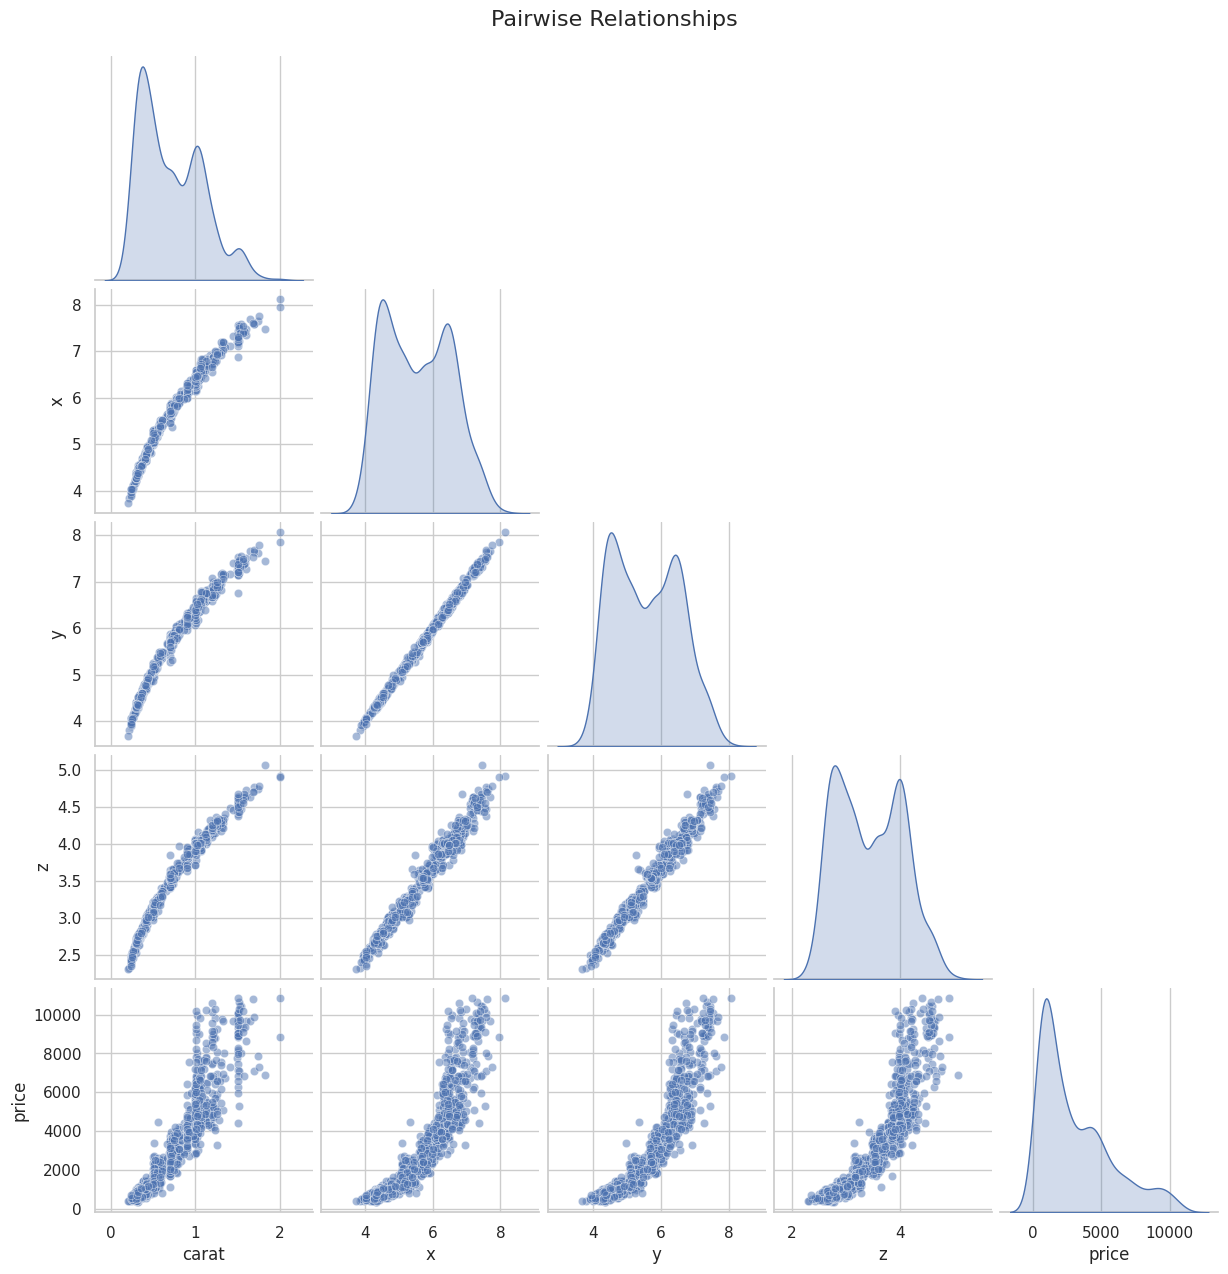

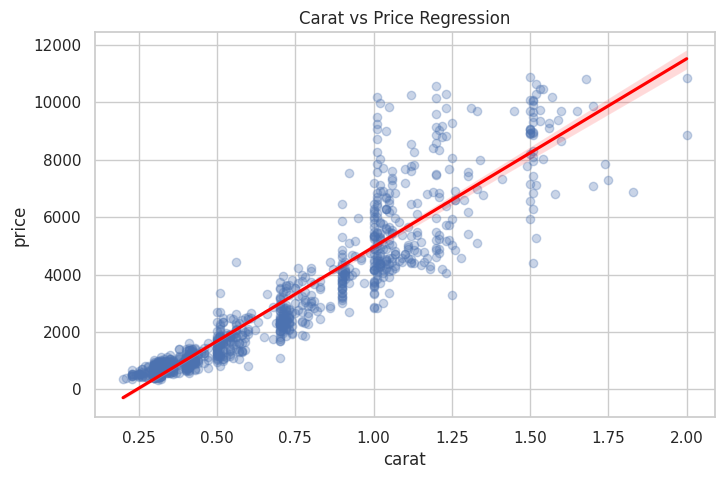

In [14]:
# 4. Scatterplot Matrix & 5. Regression Line (Sampled to prevent performance bottlenecks)
sample_df = df.sample(1000, random_state=42)
sns.pairplot(sample_df[['carat', 'x', 'y', 'z', 'price']], corner=True, diag_kind='kde', plot_kws={'alpha': 0.5})
plt.suptitle("Pairwise Relationships", y=1.02, fontsize=16)
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(data=sample_df, x='carat', y='price', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Carat vs Price Regression")
plt.show()

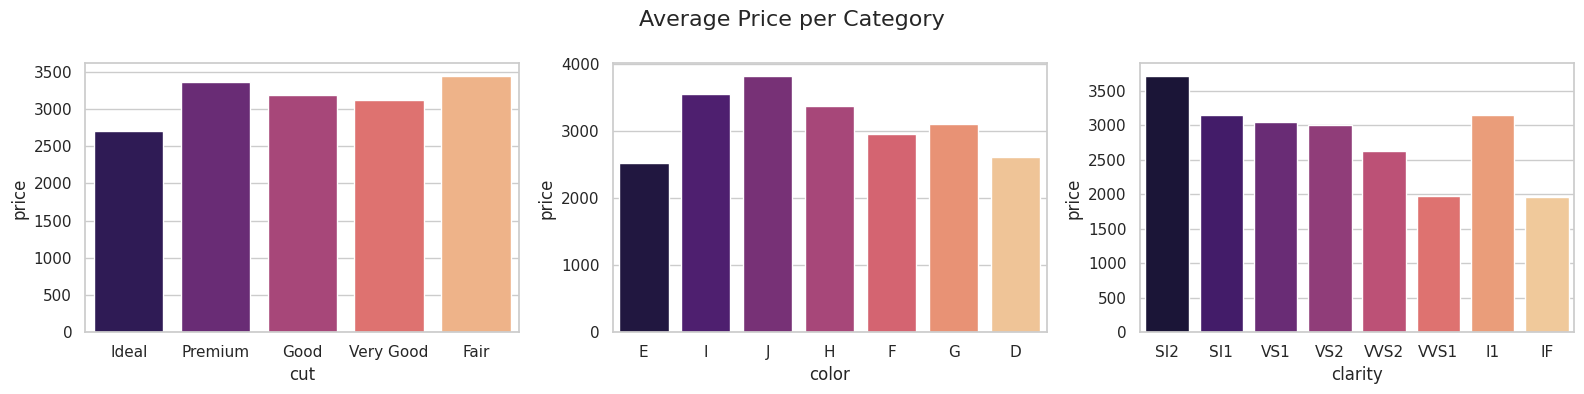

In [15]:
# 6. Average Price Bar Plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(['cut', 'color', 'clarity']):
    sns.barplot(data=df, x=col, y='price', ax=axes[i], errorbar=None, palette='magma')
plt.suptitle("Average Price per Category", fontsize=16)
plt.tight_layout()
plt.show()

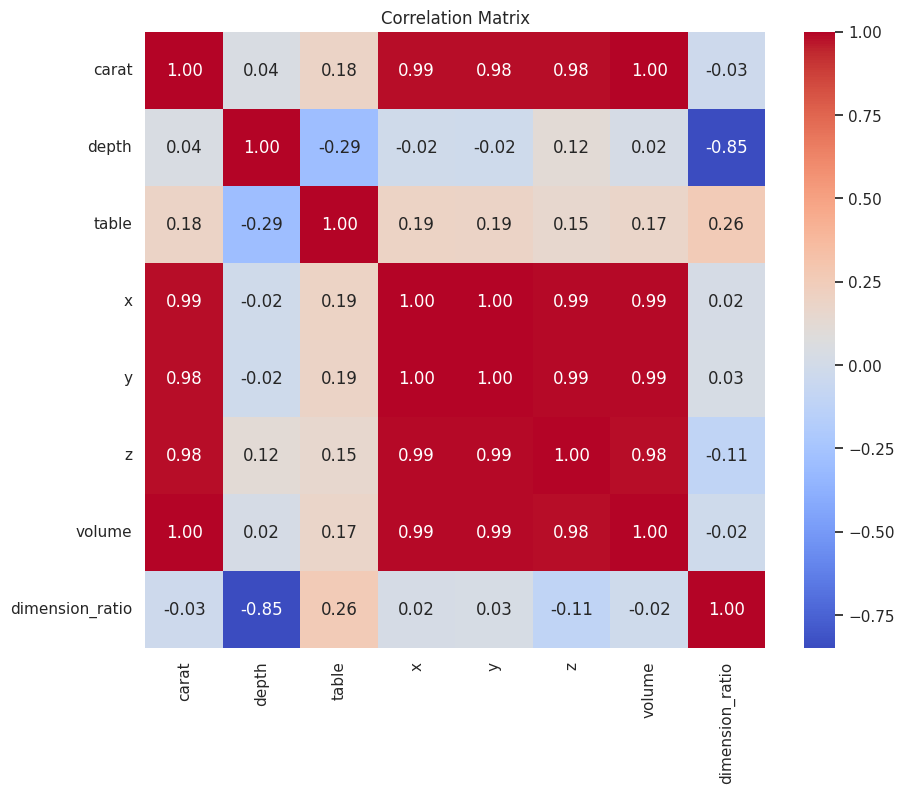


--- VIF Scores ---
        Feature   VIF Score
              z 1410.610465
         volume  751.786765
          carat  717.442519
              y  686.651097
              x  626.594857
dimension_ratio   13.458502
          depth   11.187172
          table    1.401595


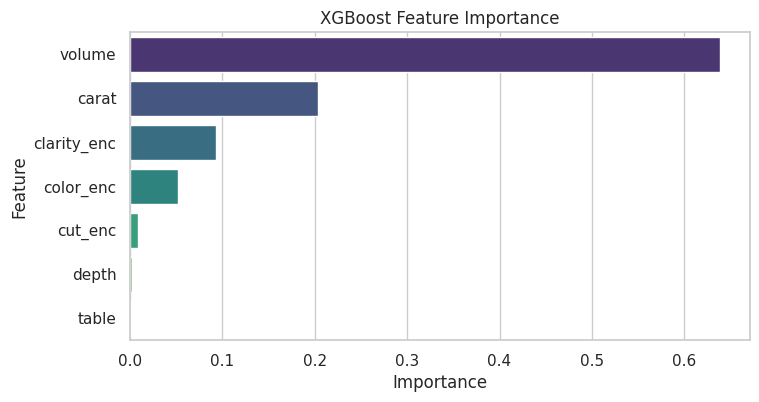


--- RFE Results ---
    Feature  Kept  Rank
      carat  True     1
      depth  True     1
      table  True     1
  color_enc  True     1
clarity_enc  True     1
    cut_enc False     2
     volume False     3


In [16]:
num_features_to_check = ['carat','depth', 'table', 'x', 'y', 'z', 'volume', 'dimension_ratio']

# 1. Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_features_to_check].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# 2. Variance Inflation Factor (VIF)
vif_data = pd.DataFrame()
vif_data["Feature"] = num_features_to_check
vif_data["VIF Score"] = [variance_inflation_factor(df[num_features_to_check].values, i) for i in range(len(num_features_to_check))]
print("\n--- VIF Scores ---")
print(vif_data.sort_values(by="VIF Score", ascending=False).to_string(index=False))

# Dropping highly collinear features (x, y, z correlate perfectly with volume/carat)
df_reduced = df.drop(columns=['x', 'y', 'z', 'dimension_ratio', 'price_per_carat', 'carat_category'])

# 3. Encoding Categorical Variables
encoder = OrdinalEncoder()
df_reduced[['cut_enc', 'color_enc', 'clarity_enc']] = encoder.fit_transform(df_reduced[['cut', 'color', 'clarity']])

# 4. Feature Importance (XGBoost)
features_eval = ['carat', 'depth', 'table', 'volume', 'cut_enc', 'color_enc', 'clarity_enc']
X_eval = df_reduced[features_eval]
y_eval = df_reduced['price_inr']

xgb_fs = XGBRegressor(random_state=42).fit(X_eval, y_eval)
imp_df = pd.DataFrame({'Feature': X_eval.columns, 'Importance': xgb_fs.feature_importances_})
plt.figure(figsize=(8, 4))
sns.barplot(data=imp_df.sort_values(by='Importance', ascending=False), x='Importance', y='Feature', palette='viridis')
plt.title("XGBoost Feature Importance")
plt.show()

# 5. Recursive Feature Elimination (RFE)
selector = RFE(LinearRegression(), n_features_to_select=5, step=1).fit(X_eval, y_eval)
rfe_res = pd.DataFrame({'Feature': X_eval.columns, 'Kept': selector.support_, 'Rank': selector.ranking_})
print("\n--- RFE Results ---")
print(rfe_res.sort_values(by='Rank').to_string(index=False))

# Final modeling feature set
final_features = ['carat', 'volume', 'cut_enc', 'color_enc', 'clarity_enc', 'depth', 'table']

In [17]:
X = df_reduced[final_features]
y = df_reduced['price_inr']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
pickle.dump(scaler, open('scaler.pkl', 'wb'))

# 1. Initialize Traditional ML Models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "KNN": KNeighborsRegressor()
}

results = []

# 2. Train and Evaluate Traditional Models
print("Training traditional ML models...")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)

    # Calculate metrics
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)

    results.append([name, mae, mse, rmse, r2])

# 3. Build and Train the ANN
print("\nTraining Artificial Neural Network (ANN)...")
ann = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

ann.compile(optimizer='adam', loss='mse', metrics=['mae'])
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

ann.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1 # Shows the progress bar in VS Code
)

# 4. Evaluate the ANN
ann_preds = ann.predict(X_test_scaled).flatten()
ann_mae = mean_absolute_error(y_test, ann_preds)
ann_mse = mean_squared_error(y_test, ann_preds)
ann_rmse = np.sqrt(ann_mse)
ann_r2 = r2_score(y_test, ann_preds)

results.append(["ANN (TensorFlow)", ann_mae, ann_mse, ann_rmse, ann_r2])

# 5. Compare All Models
# Convert results list to a DataFrame for clean formatting
results_df = pd.DataFrame(results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R² Score'])
results_df = results_df.sort_values(by='R² Score', ascending=False).reset_index(drop=True)

print("\n--- Model Performance Comparison ---")
print(results_df.to_string(index=False))

# 6. Save the Best Performing Model as .pkl

best_ml_model_name = results_df[results_df['Model'] != 'ANN (TensorFlow)'].iloc[0]['Model']
best_ml_model = models[best_ml_model_name]

print(f"\nSaving the best model ({best_ml_model_name}) as .pkl file...")
pickle.dump(best_ml_model, open('best_regression_model.pkl', 'wb'))
print("✅ Successfully saved 'best_regression_model.pkl'")

Training traditional ML models...

Training Artificial Neural Network (ANN)...
Epoch 1/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 135729676288.0000 - mae: 280555.9375 - val_loss: 133730148352.0000 - val_mae: 276804.4062
Epoch 2/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 131642671104.0000 - mae: 275888.2188 - val_loss: 122370793472.0000 - val_mae: 263987.6875
Epoch 3/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 104011382784.0000 - mae: 242856.6562 - val_loss: 75258937344.0000 - val_mae: 203385.7969
Epoch 4/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 48983576576.0000 - mae: 157793.7500 - val_loss: 25627062272.0000 - val_mae: 111840.3828
Epoch 5/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 18433521664.0000 - mae: 93483.4609 - val_loss: 12404131840.0000 - val_mae: 77084.4531
Epoch 6/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 10599675904.0000 - mae: 70539.3203 - val_loss: 8436038656.0000 - val_mae: 62851.1992
Epoch 7/50
124/124 ━━━━━━━━━━━━━━

In [18]:
#5.1 Data Preparation & Encoding

# 1. Encode Categorical Variables
encoder = OrdinalEncoder()
df[['cut_enc', 'color_enc', 'clarity_enc']] = encoder.fit_transform(df[['cut', 'color', 'clarity']])

# 2. Define Clustering Features (Dropping 'price' to segment strictly by physical traits)
# Assuming 'volume' was created in your feature engineering step
cluster_features = ['carat', 'volume', 'cut_enc', 'color_enc', 'clarity_enc', 'depth', 'table']
X_cluster = df[cluster_features]

# 3. Scale the Data (Mandatory for K-Means and PCA)
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

Evaluating clusters. This might take a minute...


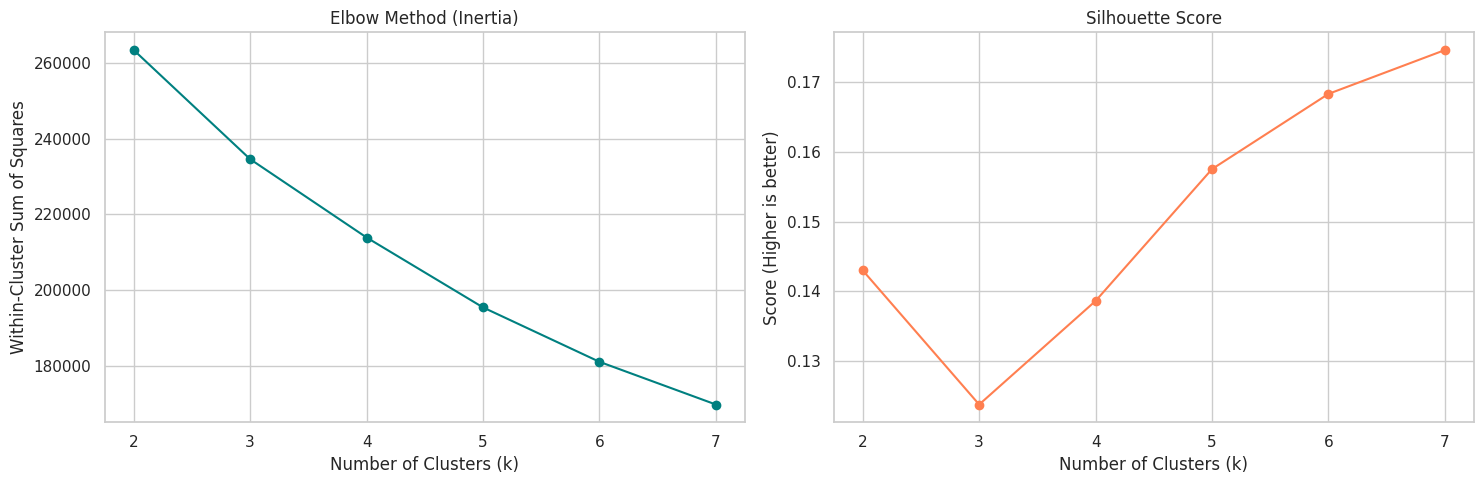

In [19]:
#5.2 Finding the Optimal Number of Clusters

inertia = []
sil_scores = []
k_range = range(2, 8)

# Note: Silhouette score can be computationally heavy.
# If your dataset is huge (>50k rows), we sample it to prevent memory crashes.
sample_size = min(10000, len(X_cluster_scaled))
X_sample = X_cluster_scaled[:sample_size]

print("Evaluating clusters. This might take a minute...")
for k in k_range:
    # n_init=10 runs the algorithm 10 times with different centroid seeds and picks the best one
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertia.append(km.inertia_)

    # Calculate Silhouette Score on the sample
    score = silhouette_score(X_sample, km.labels_[:sample_size])
    sil_scores.append(score)

# Plotting the Evaluation Metrics
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Method
axes[0].plot(k_range, inertia, marker='o', color='teal')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Within-Cluster Sum of Squares')

# Silhouette Score
axes[1].plot(k_range, sil_scores, marker='o', color='coral')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Score (Higher is better)')
plt.tight_layout()
plt.show()

In [20]:
#5.3 Fitting K-Means & Naming the Segments

# 1. Fit Final Model
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster_ID'] = final_kmeans.fit_predict(X_cluster_scaled)

# 2. Profile the Clusters to determine naming
# We bring 'price' back into the evaluation here just to see what the algorithm captured
profile_df = df.groupby('Cluster_ID')[['carat', 'price', 'volume']].mean().sort_values(by='price')

print("\n--- Cluster Profiles (Averages) ---")
print(profile_df)

# 3. Dynamic Cluster Naming Approach
# Based on the sorted average price and carat, we map the names dynamically
cluster_mapping = {
    profile_df.index[0]: "Affordable Small Diamonds",  # Lowest avg price/carat
    profile_df.index[1]: "Mid-range Balanced Diamonds",# Middle avg price/carat
    profile_df.index[2]: "Premium Heavy Diamonds"      # Highest avg price/carat
}

df['Market_Segment'] = df['Cluster_ID'].map(cluster_mapping)

print("\nSegment Distribution:")
print(df['Market_Segment'].value_counts())


--- Cluster Profiles (Averages) ---
               carat        price      volume
Cluster_ID                                   
1           0.474778  1500.625854   77.958354
2           0.494233  1551.887893   80.653113
0           1.127111  5831.371637  182.742300

Segment Distribution:
Market_Segment
Affordable Small Diamonds      18148
Premium Heavy Diamonds         17170
Mid-range Balanced Diamonds    14058
Name: count, dtype: int64


In [21]:
#5.4 Dimensionality Reduction (PCA) & Visualization

import plotly.express as px

# 1. Reduce features to 3 Principal Components (Same as before)
pca = PCA(n_components=3)
pca_components = pca.fit_transform(X_cluster_scaled)

df['PCA1'] = pca_components[:, 0]
df['PCA2'] = pca_components[:, 1]
df['PCA3'] = pca_components[:, 2]

# 2. Plot 3D Scatter Plot using Plotly
# Define the exact color mapping you used
color_map = {
    'Affordable Small Diamonds': '#1f77b4',
    'Mid-range Balanced Diamonds': '#2ca02c',
    'Premium Heavy Diamonds': '#d62728'
}

# Create the interactive figure
fig = px.scatter_3d(
    df,
    x='PCA1',
    y='PCA2',
    z='PCA3',
    color='Market_Segment',
    color_discrete_map=color_map,
    opacity=0.6,
    title='Diamond Market Segments (3D PCA Projection)'
)

# Customize the layout and axis labels to match your original plot
fig.update_layout(
    scene=dict(
        xaxis_title='PC1 (Size/Weight Focus)',
        yaxis_title='PC2 (Quality Focus)',
        zaxis_title='PC3 (Proportions)'
    ),
    legend_title_text='Market Segment',
    margin=dict(l=0, r=0, b=0, t=50) # Reduces empty whitespace around the plot
)

# Adjust marker size to make it look clean (similar to s=20 in matplotlib)
fig.update_traces(marker=dict(size=3))

# Display the interactive plot
fig.show()

In [22]:
#5.5 Model Pickling for Deployment

# Save the Clustering Model
pickle.dump(final_kmeans, open('kmeans_clustering_model.pkl', 'wb'))

# CRITICAL: Save the specific scaler used for clustering!
# The Streamlit app must scale user inputs using this exact same scaler before predicting the cluster.
pickle.dump(scaler_cluster, open('scaler_cluster.pkl', 'wb'))

print("✅ Successfully saved 'kmeans_clustering_model.pkl' and 'scaler_cluster.pkl'")

✅ Successfully saved 'kmeans_clustering_model.pkl' and 'scaler_cluster.pkl'


In [23]:
# Profile & Export for BI Tools
print("\n--- Cluster Profiles ---")
# Copy the cluster labels to df_reduced
df_reduced['Market_Segment'] = df['Market_Segment']

print(df_reduced.groupby('Market_Segment')[['carat', 'price_inr', 'volume']].mean())

df_reduced.to_csv('Diamond_Market_Segments.csv', index=False)
print("Saved 'Diamond_Market_Segments.csv' for Power BI / Tableau reporting.")


--- Cluster Profiles ---
                                carat      price_inr      volume
Market_Segment                                                  
Affordable Small Diamonds    0.474778  138927.941572   77.958354
Mid-range Balanced Diamonds  0.494233  143673.781135   80.653113
Premium Heavy Diamonds       1.127111  539868.386114  182.742300
Saved 'Diamond_Market_Segments.csv' for Power BI / Tableau reporting.


In [24]:
%%writefile app.py
import streamlit as st
import numpy as np
import pandas as pd
import pickle

st.set_page_config(page_title="Diamond Dynamics Dashboard", page_icon="💎", layout="wide")

@st.cache_resource
def load_resources():
    reg_model = pickle.load(open('best_regression_model.pkl', 'rb'))
    kmeans = pickle.load(open('kmeans_clustering_model.pkl', 'rb'))
    scaler_reg = pickle.load(open('scaler.pkl', 'rb'))
    scaler_cluster = pickle.load(open('scaler_cluster.pkl', 'rb'))
    return reg_model, kmeans, scaler_reg, scaler_cluster

try:
    reg_model, kmeans, scaler_reg, scaler_cluster = load_resources()
except FileNotFoundError:
    st.error("⚠️ Missing model files. Run the Jupyter Notebook pipeline first.")
    st.stop()

st.title("💎 Diamond Dynamics: Valuation & Segmentation Hub")
st.markdown("---")

if 'history' not in st.session_state:
    st.session_state.history = pd.DataFrame(columns=['Carat', 'Volume', 'Cut', 'Color', 'Clarity', 'Estimated_Value_INR', 'Market_Segment'])

st.sidebar.header("Asset Specifications")
carat = st.sidebar.number_input("Carat Weight", min_value=0.1, max_value=5.0, value=0.70, step=0.01)

cut_map = {"Fair": 0, "Good": 1, "Very Good": 2, "Premium": 3, "Ideal": 4}
cut_input = st.sidebar.selectbox("Cut Grade", list(cut_map.keys()), index=4)

color_map = {"J": 0, "I": 1, "H": 2, "G": 3, "F": 4, "E": 5, "D": 6}
color_input = st.sidebar.selectbox("Color Grade", list(color_map.keys()), index=3)

clarity_map = {"I1": 0, "SI2": 1, "SI1": 2, "VS2": 3, "VS1": 4, "VVS2": 5, "VVS1": 6, "IF": 7}
clarity_input = st.sidebar.selectbox("Clarity Grade", list(clarity_map.keys()), index=4)

x = st.sidebar.number_input("Length (x) mm", min_value=0.1, max_value=15.0, value=5.7, step=0.1)
y = st.sidebar.number_input("Width (y) mm", min_value=0.1, max_value=15.0, value=5.7, step=0.1)
z = st.sidebar.number_input("Depth (z) mm", min_value=0.1, max_value=15.0, value=3.5, step=0.1)
depth = st.sidebar.number_input("Total Depth %", min_value=40.0, max_value=80.0, value=61.5)
table = st.sidebar.number_input("Table %", min_value=40.0, max_value=95.0, value=57.0)

if st.sidebar.button("Execute Analysis", type="primary"):
    volume = x * y * z
    cut_enc = cut_map[cut_input]
    color_enc = color_map[color_input]
    clarity_enc = clarity_map[clarity_input]

    raw_features = np.array([[carat, volume, cut_enc, color_enc, clarity_enc, depth, table]])

    reg_input_scaled = scaler_reg.transform(raw_features)
    cluster_input_scaled = scaler_cluster.transform(raw_features)

    predicted_price = reg_model.predict(reg_input_scaled)[0]
    cluster_id = kmeans.predict(cluster_input_scaled)[0]

    segment_names = {0: "Affordable Small Diamonds", 1: "Mid-range Balanced Diamonds", 2: "Premium Heavy Diamonds"}
    assigned_segment = segment_names.get(cluster_id, "Unclassified")

    col1, col2 = st.columns(2)
    with col1:
        st.success("### Asset Valuation")
        st.metric(label="Estimated Market Price", value=f"₹ {predicted_price:,.2f} INR")
    with col2:
        st.info("### Market Classification")
        st.metric(label="Automated Segment", value=assigned_segment)

    new_record = pd.DataFrame([{'Carat': carat, 'Volume': round(volume, 2), 'Cut': cut_input, 'Color': color_input, 'Clarity': clarity_input, 'Estimated_Value_INR': round(predicted_price, 2), 'Market_Segment': assigned_segment}])
    st.session_state.history = pd.concat([st.session_state.history, new_record], ignore_index=True)

if not st.session_state.history.empty:
    st.markdown("### 📊 Session Analysis History")
    st.dataframe(st.session_state.history, use_container_width=True)
    st.download_button(label="📥 Download History (CSV)", data=st.session_state.history.to_csv(index=False).encode('utf-8'), file_name='valuation_history.csv', mime='text/csv')

Writing app.py


In [ ]:
# Terminate any previously running instances of streamlit or tunnels
!pkill streamlit
!pkill ssh

# Run Streamlit in the background
import subprocess
import time
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.address", "127.0.0.1"])
time.sleep(5)  # Wait for Streamlit server to spin up fully

# Expose port 8501 using localhost.run SSH tunnel (completely free, zero-config, and highly stable)
print("Starting secure tunnel via localhost.run...")
print("Click on the URL ending with '.lhr.life' below to access your Streamlit app:")
!ssh -o StrictHostKeyChecking=no -R 80:127.0.0.1:8501 nokey@localhost.run

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
changed 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴Your Tunnel Password (IP Address) is: 35.221.233.155
⠙⠹⠸⠼⠴⠦⠧your url is: https://major-yaks-start.loca.lt
